In [ ]:
import cv2
import matplotlib.pyplot as plt
import math
import numpy as np
from google.colab.patches import cv2_imshow
import seaborn as sns

In [ ]:
def img_choice():
  img='/content/image.jpg'
  print("1.Color")
  print("2.Gray")
  a=(input("Enter your choice : "))
  if a=="1":
    print("Color Image")
    clr_img=cv2.imread(img)
    return a,clr_img
  
  elif a=="2":
    print("Gray Image")
    gr_img=cv2.imread(img,0)
    return a,gr_img

  else:
    print("Invalid Choice")
    img_choice()

In [ ]:
def gamma(im):
  ga=np.array(im.max()*(im/im.max())**2.3).astype('uint8')
  return ga

In [ ]:
def normal_image(im):
  norm_img3 = cv2.normalize(im, None, alpha=0.2, beta=1, norm_type=cv2.NORM_MINMAX, dtype=cv2.CV_32F)
  norm_img = (255*norm_img3).astype(np.uint8)
  return norm_img

In [ ]:
def vec(im):
  def pixelVal(pix, r1, s1, r2, s2):
    if(0 <= pix and pix <= r1):
      return (s1 / r1)*pix
    elif (r1 < pix and pix <= r2):
      return ((s2 - s1)/(r2 - r1)) * (pix - r1) + s1
    else:
      return ((255 - s2)/(255 - r2)) * (pix - r2) + s2

  r1 = im.min()
  s1 = 10
  r2 = im.max()
  s2 = 275
  pixelVal_vec = np.vectorize(pixelVal)
  contrast_stretched = pixelVal_vec(im, r1, s1, r2, s2)
  return contrast_stretched

In [ ]:
def main():
  print("Contrast Stretching Methods")
  while True:
    print("1.Gamma Transformation")
    print("2.Normalization Transformation")
    print("3.Vectorization Transformation")
    print("4.Exit")

    d=int(input("Enter your choice : "))
    if d==1:
      cg,imge=img_choice()
      gam_img=gamma(imge)
      print('','Original Image\t\t\t\t\t Gamma Image')
      imm=np.concatenate((imge,gam_img),axis=1)
      cv2_imshow(imm)
      print()
      if cg=='1':
        print("\nOriginal Image Histogram")
        color = ('b','g','r')
        for k,color in enumerate(color):
          histogram = cv2.calcHist([imge],[k],None,[256],[0,256])
          plt.plot(histogram,color = color)
          plt.xlim(0,255)
          plt.show()
        color = ('b','g','r')
        print("\nGamma Image Histogram")
        for k,color in enumerate(color):
          histogram = cv2.calcHist([gam_img],[k],None,[256],[0,256])
          plt.plot(histogram,color = color)
          plt.xlim(0,255)
          plt.show()
      else:
        print("\nOriginal Image Histogram")
        plt.hist(imge.ravel(),256,[0,256])
        plt.xlim(0,255)
        plt.show()
        print("\nGamma Image Histogram")
        plt.hist(gam_img.ravel(),256, [0,256])
        plt.xlim(0,255)
        plt.show()
    elif d==2:
      ig,image=img_choice()
      nm_img=normal_image(image)
      print('','Original Image \t\t\t\t Normalized Image')
      i=np.concatenate((image,nm_img),axis=1)
      cv2_imshow(i)
      print()
      if ig=='1':
        print("\nOriginal Image Histogram")
        color = ('b','g','r')
        for k,color in enumerate(color):
          histogram = cv2.calcHist([image],[k],None,[256],[0,256])
          plt.plot(histogram,color = color)
          plt.xlim(0,255)
          plt.show()
        color = ('b','g','r')
        print("\nNormalized Image Histogram")
        for k,color in enumerate(color):
          histogram = cv2.calcHist([nm_img],[k],None,[256],[0,256])
          plt.plot(histogram,color = color)
          plt.xlim(0,255)
          plt.show()
      else:
        print("\nOriginal Image Histogram")
        plt.hist(image.ravel(),256,[0,256])
        plt.xlim(0,255)
        plt.show()
        print("\nNormalized Image Histogram")
        plt.hist(nm_img.ravel(),256, [0,256])
        plt.xlim(0,255)
        plt.show()
      
    elif d==3:
      cg,img1=img_choice()
      pix_img=vec(img1)
      print('','Original Image \t\t\t\t Vectorized Image')
      im=np.concatenate((img1,pix_img),axis=1)
      cv2_imshow(im)
      print()
      if cg=='1':
        print("\nOriginal Image Histogram")
        color = ('b','g','r')
        for k,color in enumerate(color):
          histogram = cv2.calcHist([np.float32(img1)],[k],None,[256],[0,256])
          plt.plot(histogram,color = color)
          plt.xlim(0,255)
          plt.show()
        color = ('b','g','r')
        print("\nVectorized Image Histogram")
        for k,color in enumerate(color):
          histogram = cv2.calcHist([np.float32(pix_img)],[k],None,[256],[0,256])
          plt.plot(histogram,color = color)
          plt.xlim(0,255)
          plt.show()
      else:
        print("\nOriginal Image Histogram")
        plt.hist(img1.ravel(),256,[0,256])
        plt.xlim(0,255)
        plt.show()
        print("\nVectorized Image Histogram")
        plt.hist(pix_img.ravel(),256, [0,256])
        plt.xlim(0,255)
        plt.show()
    elif d==4:

      print("\nEND")
      break
    else:
      print("Invalid Choice")


Contrast Stretching Methods
1.Gamma Transformation
2.Normalization Transformation
3.Vectorization Transformation
4.Exit
Enter your choice : 1
1.Color
2.Gray
Enter your choice : 1
Color Image
 Original Image					 Gamma Image


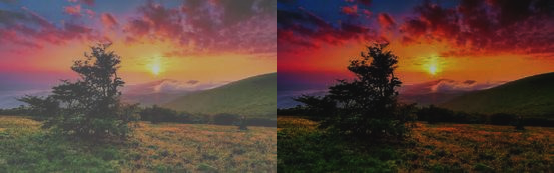



Original Image Histogram


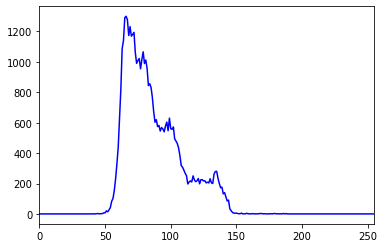

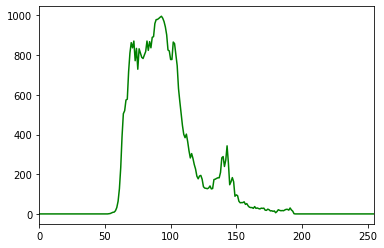

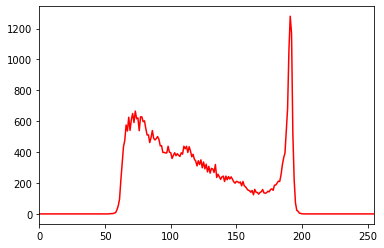


Gamma Image Histogram


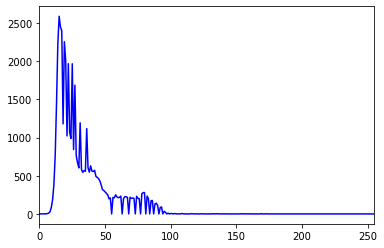

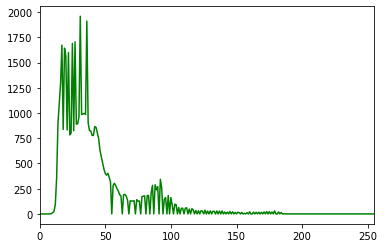

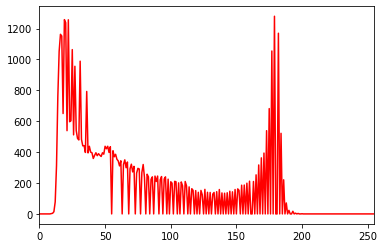

1.Gamma Transformation
2.Normalization Transformation
3.Vectorization Transformation
4.Exit
Enter your choice : 1
1.Color
2.Gray
Enter your choice : 2
Gray Image
 Original Image					 Gamma Image


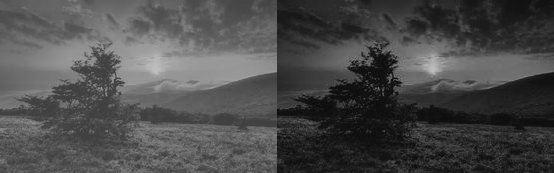



Original Image Histogram


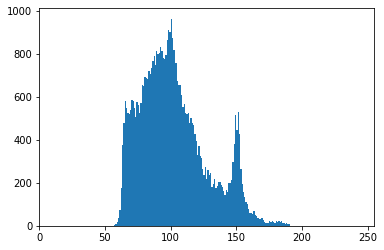


Gamma Image Histogram


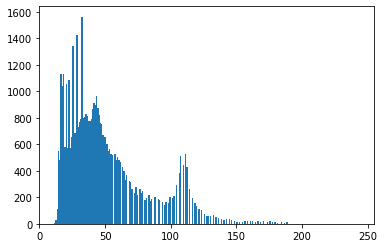

1.Gamma Transformation
2.Normalization Transformation
3.Vectorization Transformation
4.Exit
Enter your choice : 2
1.Color
2.Gray
Enter your choice : 1
Color Image
 Original Image 				 Normalized Image


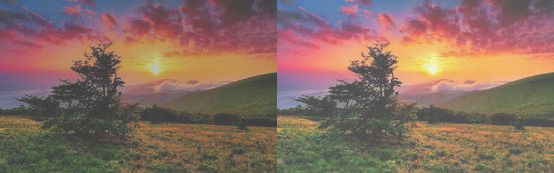



Original Image Histogram


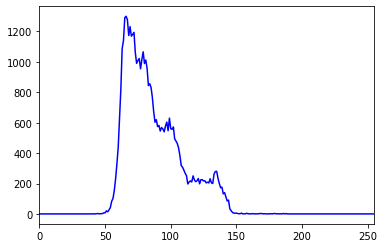

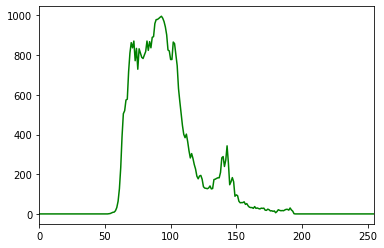

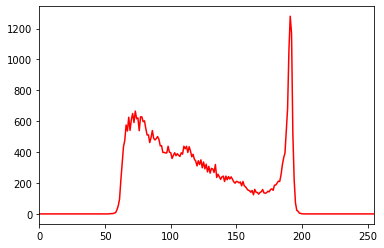


Normalized Image Histogram


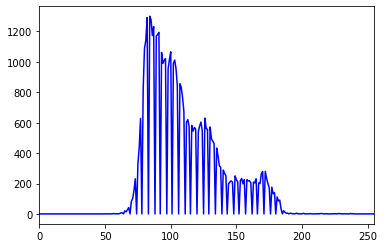

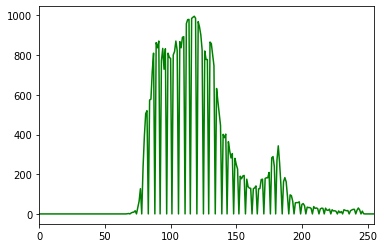

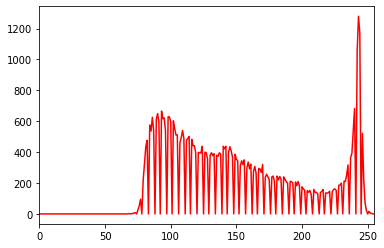

1.Gamma Transformation
2.Normalization Transformation
3.Vectorization Transformation
4.Exit
Enter your choice : 2
1.Color
2.Gray
Enter your choice : 2
Gray Image
 Original Image 				 Normalized Image


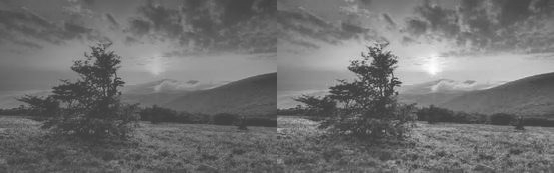



Original Image Histogram


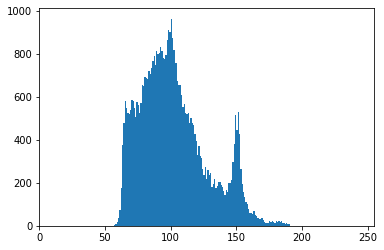


Normalized Image Histogram


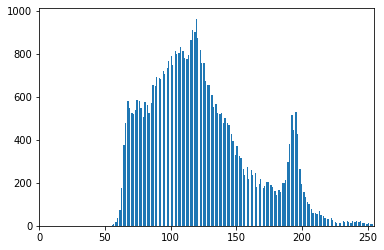

1.Gamma Transformation
2.Normalization Transformation
3.Vectorization Transformation
4.Exit
Enter your choice : 3
1.Color
2.Gray
Enter your choice : 1
Color Image
 Original Image 				 Vectorized Image


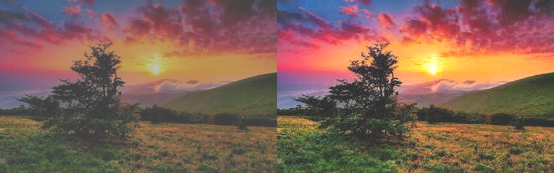



Original Image Histogram


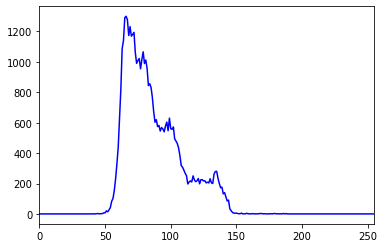

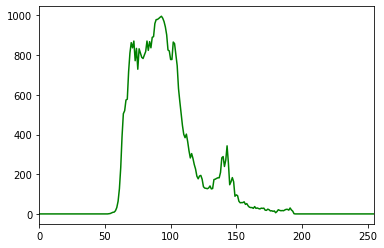

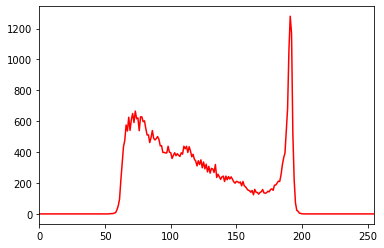


Vectorized Image Histogram


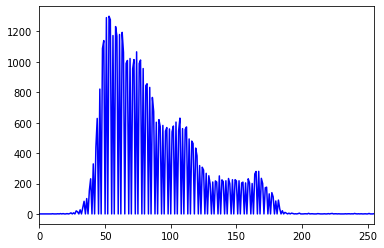

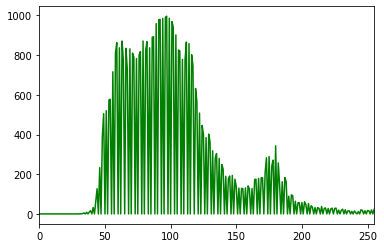

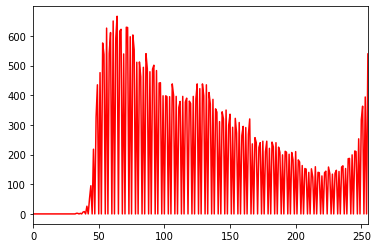

1.Gamma Transformation
2.Normalization Transformation
3.Vectorization Transformation
4.Exit
Enter your choice : 3
1.Color
2.Gray
Enter your choice : 2
Gray Image
 Original Image 				 Vectorized Image


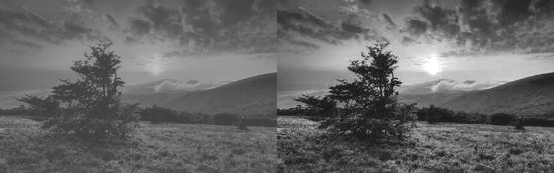



Original Image Histogram


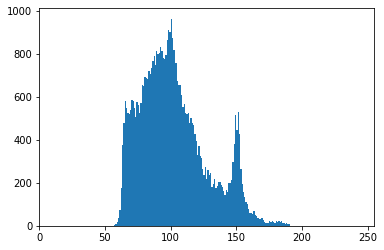


Vectorized Image Histogram


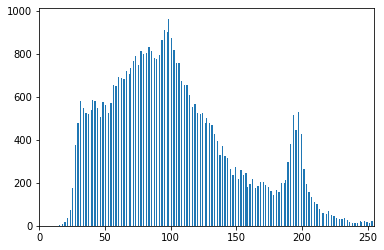

1.Gamma Transformation
2.Normalization Transformation
3.Vectorization Transformation
4.Exit
Enter your choice : 4

END


In [ ]:
main()